In [1]:
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
votacao = pd.read_csv('detalhe_votacao_munzona_2026\\detalhe_votacao_munzona_2026_BR.csv', encoding='latin1', sep=';')

In [4]:
votacao.head()

,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,...,QT_TOTAL_VOTOS_ANUL_SUBJUD,QT_VOTOS_NOMINAIS_ANUL_SUBJUD,QT_VOTOS_LEGENDA_ANUL_SUBJUD,QT_VOTOS_BRANCOS,QT_TOTAL_VOTOS_NULOS,QT_VOTOS_NULOS,QT_VOTOS_NULOS_TECNICOS,QT_VOTOS_ANULADOS_APU_SEP,HH_ULTIMA_TOTALIZACAO,DT_ULTIMA_TOTALIZACAO
0,11/10/2026,19:33:58,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,98,251,251,0,0,19:17:32,04/10/2026
1,11/10/2026,19:33:58,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,124,357,356,1,0,19:11:27,04/10/2026
2,11/10/2026,19:33:58,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,56,159,159,0,0,18:55:24,04/10/2026
3,11/10/2026,19:33:58,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,135,385,385,0,0,19:16:23,04/10/2026
4,11/10/2026,19:33:58,2026,2,Eleição Ordinária,1,6257,Eleição Geral Federal 2026,04/10/2026,F,...,0,0,0,48,226,226,0,0,18:17:01,04/10/2026


In [7]:
votacao['BRANCOS_NULOS'] = votacao['QT_VOTOS_BRANCOS'] + votacao['QT_TOTAL_VOTOS_NULOS']

In [3]:
votacao[votacao.NR_TURNO == 1].head(1).T

,0
DT_GERACAO,06/10/2026
HH_GERACAO,14:03:43
ANO_ELEICAO,2026
CD_TIPO_ELEICAO,2
NM_TIPO_ELEICAO,Eleição Ordinária
NR_TURNO,1
CD_ELEICAO,6257
DS_ELEICAO,Eleição Geral Federal 2026
DT_ELEICAO,04/10/2026
TP_ABRANGENCIA,F


In [ ]:
votacao

In [8]:
vot_mun = votacao.pivot_table(index=['SG_UF','CD_MUNICIPIO','NM_MUNICIPIO'], values='BRANCOS_NULOS', aggfunc='sum', margins=True).reset_index()
vot_mun

,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,BRANCOS_NULOS
0,AC,1007,BUJARI,349
1,AC,1015,CAPIXABA,215
2,AC,1023,PORTO ACRE,481
3,AC,1031,SANTA ROSA DO PURUS,142
4,AC,1040,MARECHAL THAUMATURGO,274
...,...,...,...,...
5753,ZZ,99473,BAREIN,2
5754,ZZ,99490,ORLANDO,126
5755,ZZ,99503,EDIMBURGO,17
5756,ZZ,99511,MARSELHA,7


In [9]:
vot_uf = votacao.pivot_table(index=['SG_UF',], values='BRANCOS_NULOS', aggfunc='sum', margins=True).reset_index()
vot_uf

,SG_UF,BRANCOS_NULOS
0,AC,19264
1,AL,119572
2,AM,63786
3,AP,11704
4,BA,493310
5,CE,292657
6,DF,58588
7,ES,101204
8,GO,143764
9,MA,149904


In [11]:
mapa = gpd.read_file('BR_Municipios_2021\\BR_Municipios_2021.shp')

In [12]:
mapa_uf = gpd.read_file('BR_UF_2021\\BR_UF_2021.shp')

In [13]:
vot_uf

,SG_UF,BRANCOS_NULOS
0,AC,19264
1,AL,119572
2,AM,63786
3,AP,11704
4,BA,493310
5,CE,292657
6,DF,58588
7,ES,101204
8,GO,143764
9,MA,149904


In [14]:
vot_uf[vot_uf.columns[1:]]

,BRANCOS_NULOS
0,19264
1,119572
2,63786
3,11704
4,493310
5,292657
6,58588
7,101204
8,143764
9,149904


In [17]:
mapa.NM_MUN = mapa.NM_MUN.str.upper()

In [18]:
mapa.head()

,CD_MUN,NM_MUN,SIGLA,AREA_KM2,geometry
0,1100015,ALTA FLORESTA D'OESTE,RO,7067.127,"POLYGON ((-62.19465 -11.82746, -62.19332 -11.8..."
1,1100023,ARIQUEMES,RO,4426.571,"POLYGON ((-62.53648 -9.73222, -62.52765 -9.736..."
2,1100031,CABIXI,RO,1314.352,"POLYGON ((-60.37119 -13.36655, -60.37134 -13.3..."
3,1100049,CACOAL,RO,3793.000,"POLYGON ((-61.0008 -11.29737, -61.00103 -11.39..."
4,1100056,CEREJEIRAS,RO,2783.300,"POLYGON ((-61.49976 -13.00525, -61.49809 -13.0..."


In [19]:
vot_mun.head()

,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,BRANCOS_NULOS
0,AC,1007,BUJARI,349
1,AC,1015,CAPIXABA,215
2,AC,1023,PORTO ACRE,481
3,AC,1031,SANTA ROSA DO PURUS,142
4,AC,1040,MARECHAL THAUMATURGO,274


In [20]:
mapa.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   CD_MUN    5572 non-null   str     
 1   NM_MUN    5572 non-null   str     
 2   SIGLA     5572 non-null   str     
 3   AREA_KM2  5572 non-null   float64 
 4   geometry  5572 non-null   geometry
dtypes: float64(1), geometry(1), str(3)
memory usage: 217.8 KB


In [21]:
vot_mun.info()

<class 'pandas.DataFrame'>
RangeIndex: 5758 entries, 0 to 5757
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   SG_UF          5758 non-null   str   
 1   CD_MUNICIPIO   5758 non-null   object
 2   NM_MUNICIPIO   5758 non-null   str   
 3   BRANCOS_NULOS  5758 non-null   int64 
dtypes: int64(1), object(1), str(2)
memory usage: 180.1+ KB


In [23]:
mapa_vot = mapa.merge(vot_mun, left_on=['SIGLA', 'NM_MUN'], right_on=['SG_UF', 'NM_MUNICIPIO'])
mapa_vot

,CD_MUN,NM_MUN,SIGLA,AREA_KM2,geometry,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,BRANCOS_NULOS
0,1100023,ARIQUEMES,RO,4426.571,"POLYGON ((-62.53648 -9.73222, -62.52765 -9.736...",RO,78,ARIQUEMES,1070
1,1100031,CABIXI,RO,1314.352,"POLYGON ((-60.37119 -13.36655, -60.37134 -13.3...",RO,450,CABIXI,82
2,1100049,CACOAL,RO,3793.000,"POLYGON ((-61.0008 -11.29737, -61.00103 -11.39...",RO,94,CACOAL,1218
3,1100056,CEREJEIRAS,RO,2783.300,"POLYGON ((-61.49976 -13.00525, -61.49809 -13.0...",RO,272,CEREJEIRAS,176
4,1100064,COLORADO DO OESTE,RO,1451.060,"POLYGON ((-60.50475 -12.96672, -60.50475 -12.9...",RO,230,COLORADO DO OESTE,283
...,...,...,...,...,...,...,...,...,...
5501,5222005,VIANÓPOLIS,GO,954.115,"POLYGON ((-48.42801 -16.62789, -48.42803 -16.6...",GO,96415,VIANÓPOLIS,303
5502,5222054,VICENTINÓPOLIS,GO,733.794,"POLYGON ((-49.8474 -17.57796, -49.84719 -17.57...",GO,96571,VICENTINÓPOLIS,217
5503,5222203,VILA BOA,GO,1052.593,"POLYGON ((-47.10998 -14.67195, -47.10994 -14.6...",GO,93289,VILA BOA,94
5504,5222302,VILA PROPÍCIO,GO,2181.593,"POLYGON ((-48.75572 -14.86393, -48.75502 -14.8...",GO,93505,VILA PROPÍCIO,111


In [24]:
mapa_uf_vot = mapa_uf.merge(vot_uf, left_on=['SIGLA'], right_on=['SG_UF'])

In [26]:
mapa_uf_vot

,CD_UF,NM_UF,SIGLA,NM_REGIAO,geometry,SG_UF,BRANCOS_NULOS
0,11,Rondônia,RO,Norte,"POLYGON ((-62.86662 -7.97587, -62.86017 -7.982...",RO,23021
1,12,Acre,AC,Norte,"POLYGON ((-73.1655 -7.34166, -73.0548 -7.38171...",AC,19264
2,13,Amazonas,AM,Norte,"POLYGON ((-67.32609 2.02971, -67.31682 2.00125...",AM,63786
3,14,Roraima,RR,Norte,"POLYGON ((-60.20051 5.26434, -60.19828 5.26045...",RR,7227
4,15,Pará,PA,Norte,"MULTIPOLYGON (((-46.43676 -1.01905, -46.43723 ...",PA,203332
5,16,Amapá,AP,Norte,"MULTIPOLYGON (((-50.45011 2.10924, -50.44715 2...",AP,11704
6,17,Tocantins,TO,Norte,"POLYGON ((-48.35878 -5.17008, -48.35617 -5.171...",TO,34749
7,21,Maranhão,MA,Nordeste,"MULTIPOLYGON (((-44.66115 -2.98018, -44.66157 ...",MA,149904
8,22,Piauí,PI,Nordeste,"POLYGON ((-41.78076 -2.76078, -41.77935 -2.764...",PI,94489
9,23,Ceará,CE,Nordeste,"POLYGON ((-40.49582 -2.78541, -40.49242 -2.787...",CE,292657


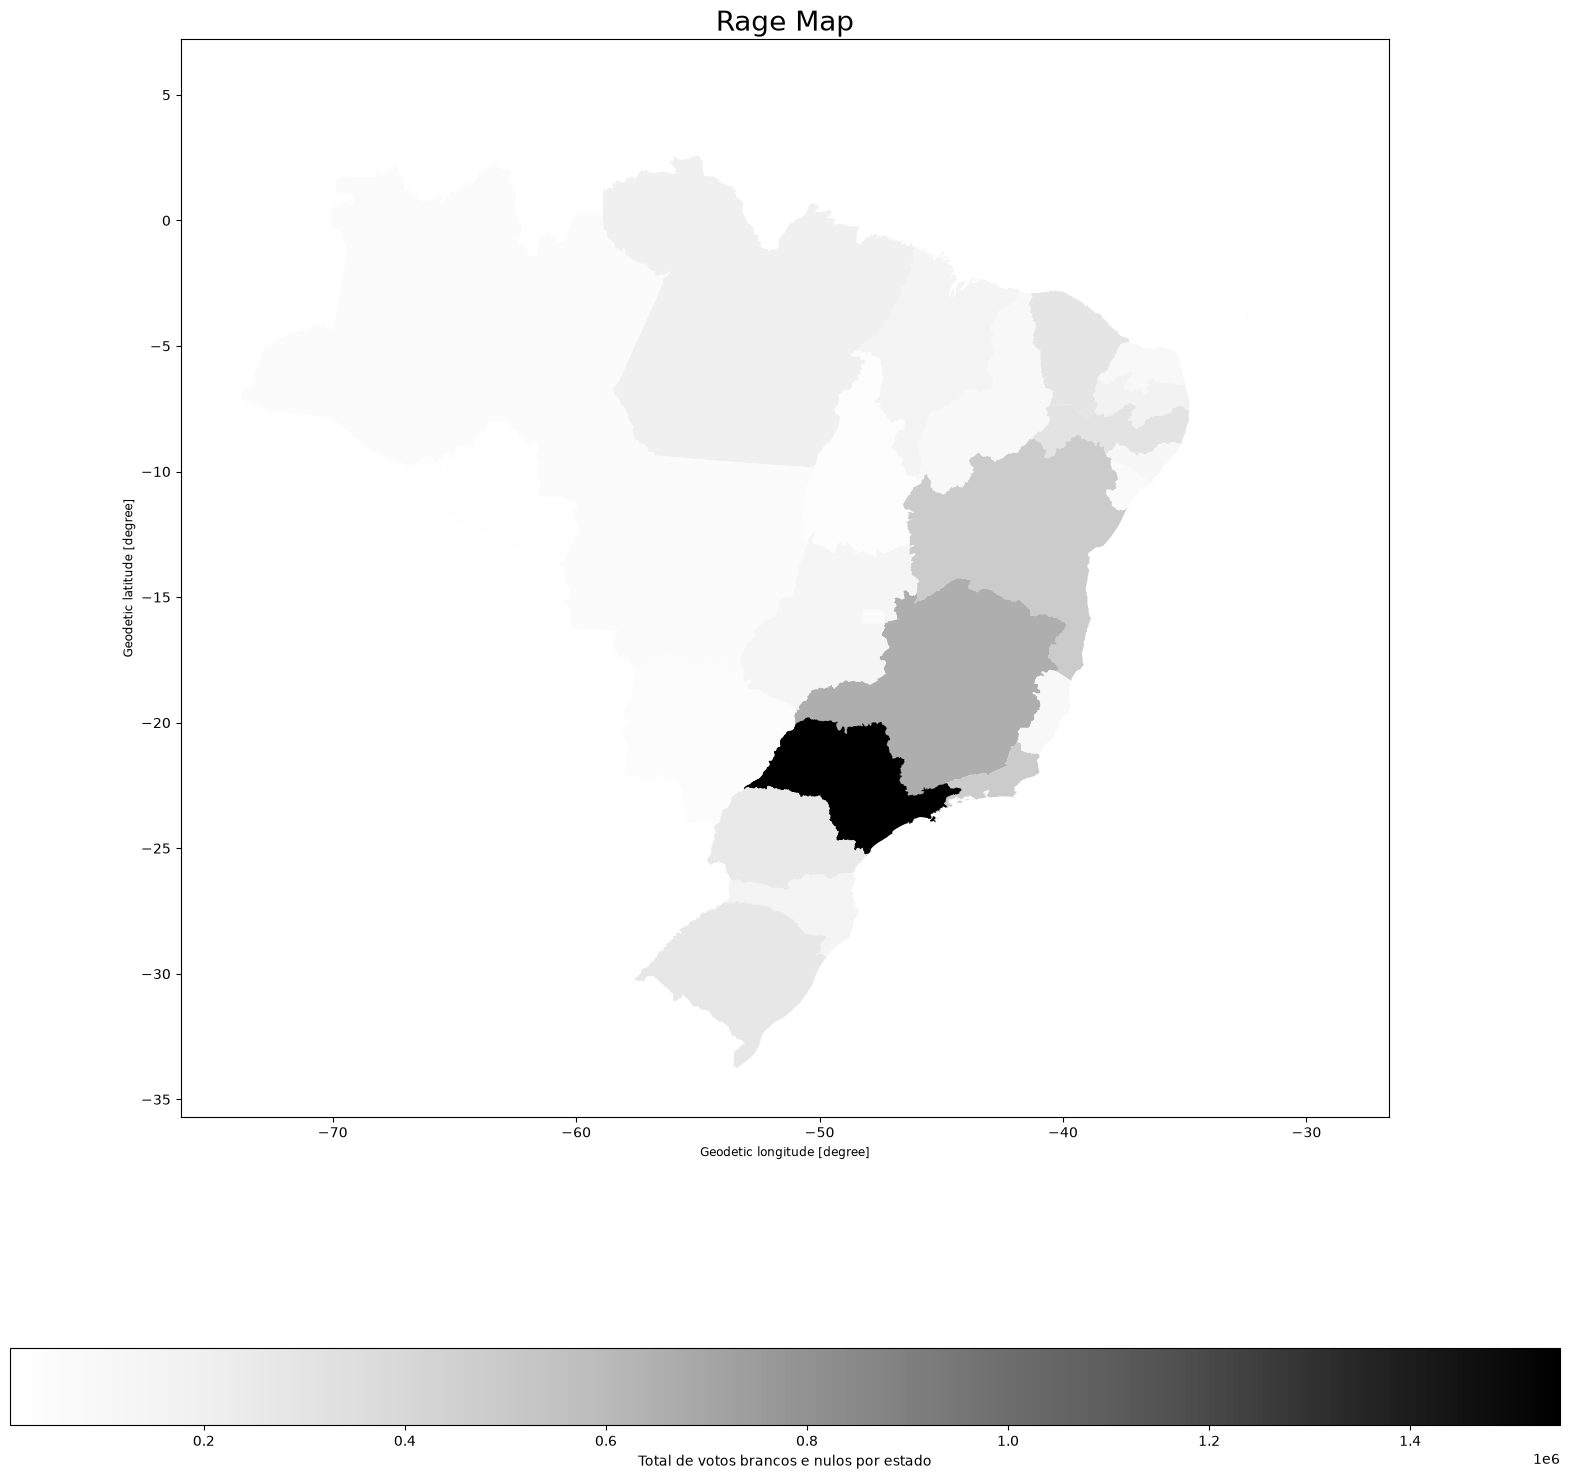

In [36]:
fig, ax = plt.subplots(figsize=(20,20))
mapa_uf_vot.plot(column='BRANCOS_NULOS',figsize=(10,10), ax=ax, legend=True, cmap='Greys', legend_kwds={'label': "Total de votos brancos e nulos por estado", 'orientation': "horizontal"})
# ax.set_axis_off();
ax.set_title("Rage Map", fontsize=20)
plt.savefig('black_null_map.pdf')

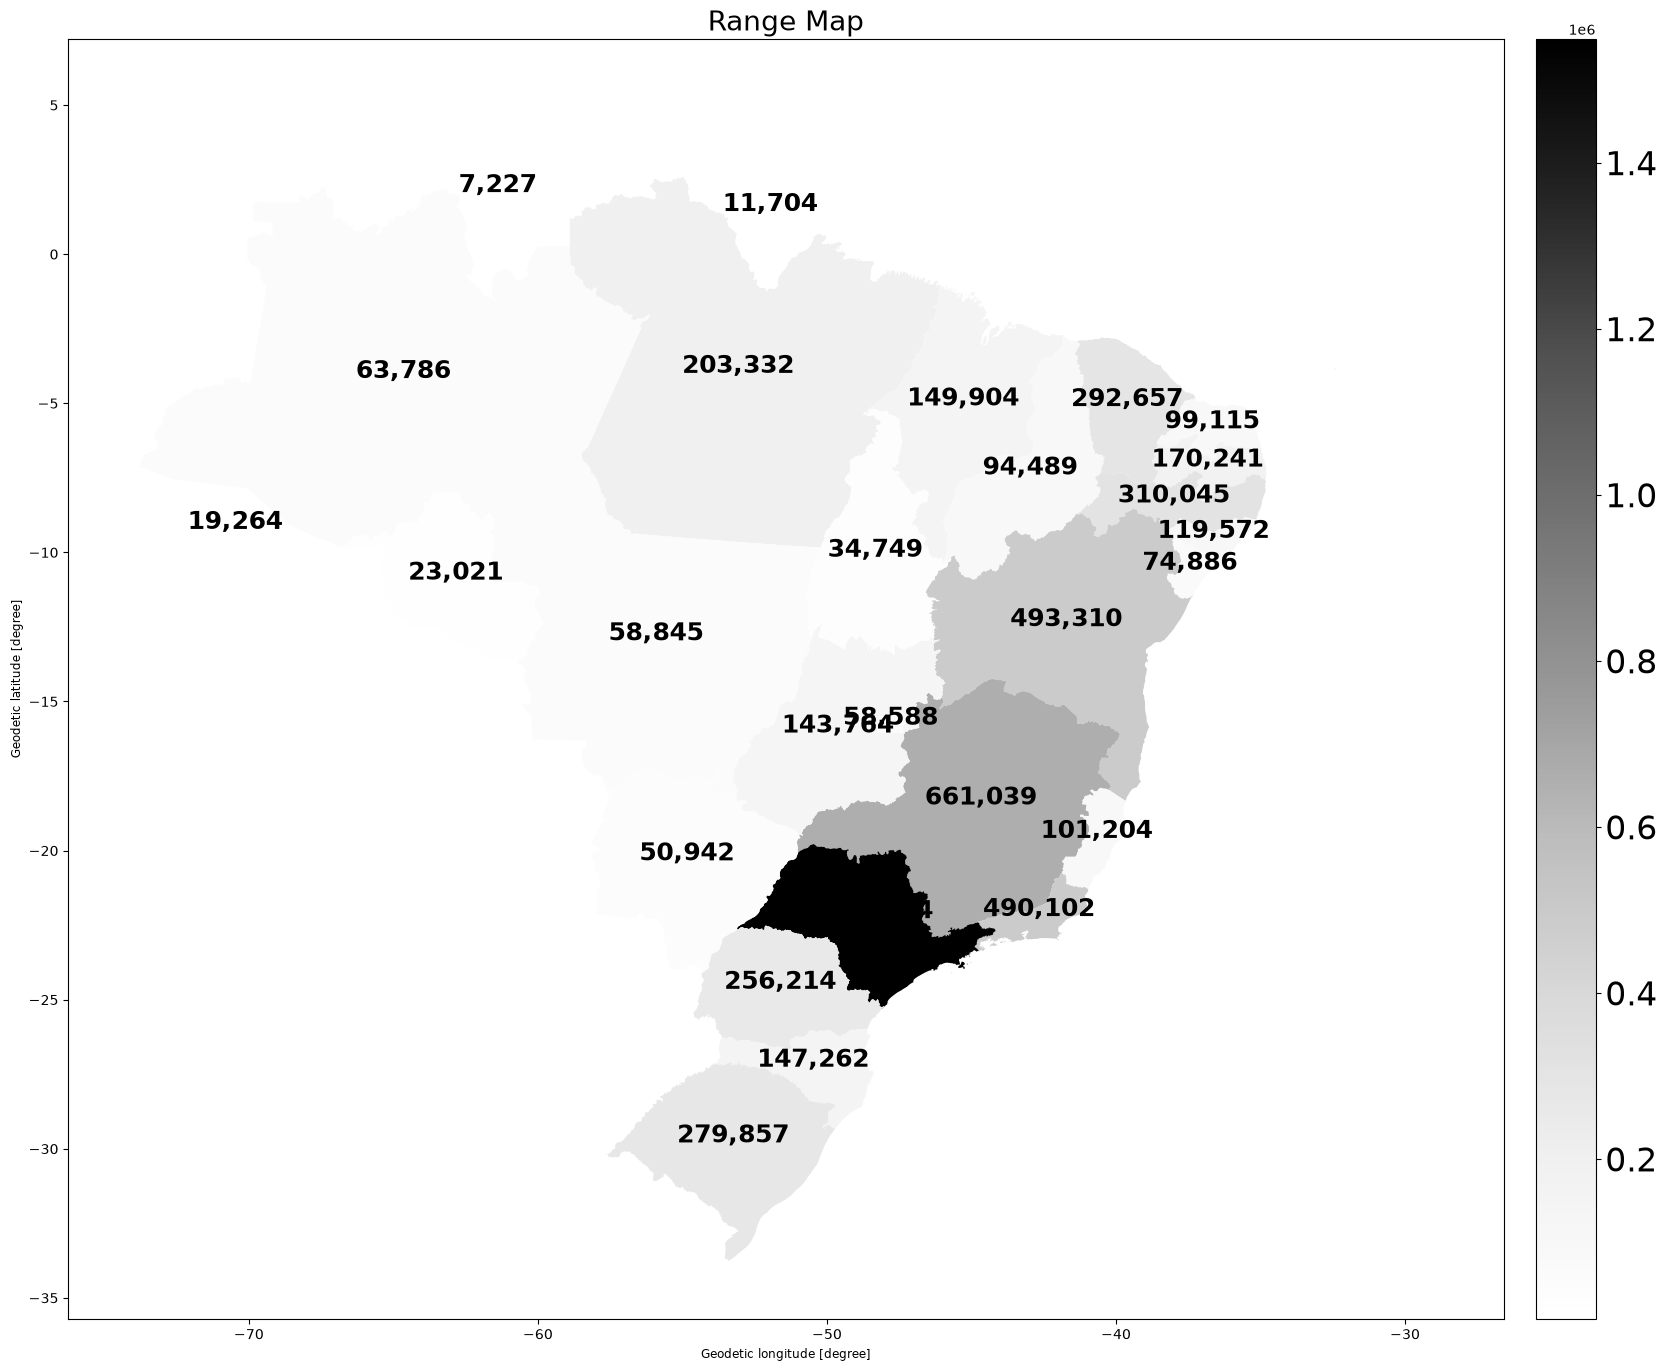

In [45]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax = plt.subplots(figsize=(20,20))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.1)
mapa_uf_vot.plot(column='BRANCOS_NULOS', cmap='Greys', figsize=(10,10), legend=True, ax=ax, cax=cax)
mapa_uf_vot.apply(lambda x: ax.annotate(text="{:,.0f}".format(x['BRANCOS_NULOS']), xy=x.geometry.centroid.coords[0], ha='center', color='black', fontsize=18, fontweight='bold'), axis=1);
# ax.set_axis_off();
for t in cax.get_yticklabels():
   t.set_fontsize(24)
ax.set_title("Range Map", fontsize=20)
# ax.set_caption('teste')
plt.savefig('range_map.pdf')

  


In [40]:
print(len(mapa), len(vot_mun[:len(mapa)]))

5572 5572


In [41]:
mapa['ufmun'] = mapa['SIGLA']+mapa['NM_MUN']

In [42]:
vot_mun['ufmun'] = vot_mun['SG_UF']+vot_mun['NM_MUNICIPIO']

In [43]:
vot_mun.info()

<class 'pandas.DataFrame'>
RangeIndex: 5717 entries, 0 to 5716
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SG_UF         5717 non-null   str    
 1   CD_MUNICIPIO  5717 non-null   object 
 2   NM_MUNICIPIO  5717 non-null   str    
 3   13            5717 non-null   float64
 4   14            5687 non-null   float64
 5   16            3440 non-null   float64
 6   21            3539 non-null   float64
 7   22            5715 non-null   float64
 8   27            3692 non-null   float64
 9   28            1669 non-null   float64
 10  29            2244 non-null   float64
 11  30            5263 non-null   float64
 12  35            2572 non-null   float64
 13  55            5687 non-null   float64
 14  70            5696 non-null   float64
 15  80            4601 non-null   float64
 16  95            5681 non-null   float64
 17  96            5682 non-null   float64
 18  All           5717 non-null   float64
 

In [44]:
mapa_vot = mapa.merge(vot_mun, on='ufmun')

In [45]:
mapa_vot['13_bin'] = mapa_vot[13] > mapa_vot[22]

In [46]:
mapa_vot['13_color'] = mapa_vot['13_bin'].apply(lambda x: 'r' if x == True else 'b')

C:\Users\adria\AppData\Local\Temp\ipykernel_32540\2273405976.py:2: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  mapa_vot.plot(column='13_bin', color=mapa_vot['13_color'], edgecolor=mapa_vot['13_color'], ax=ax)


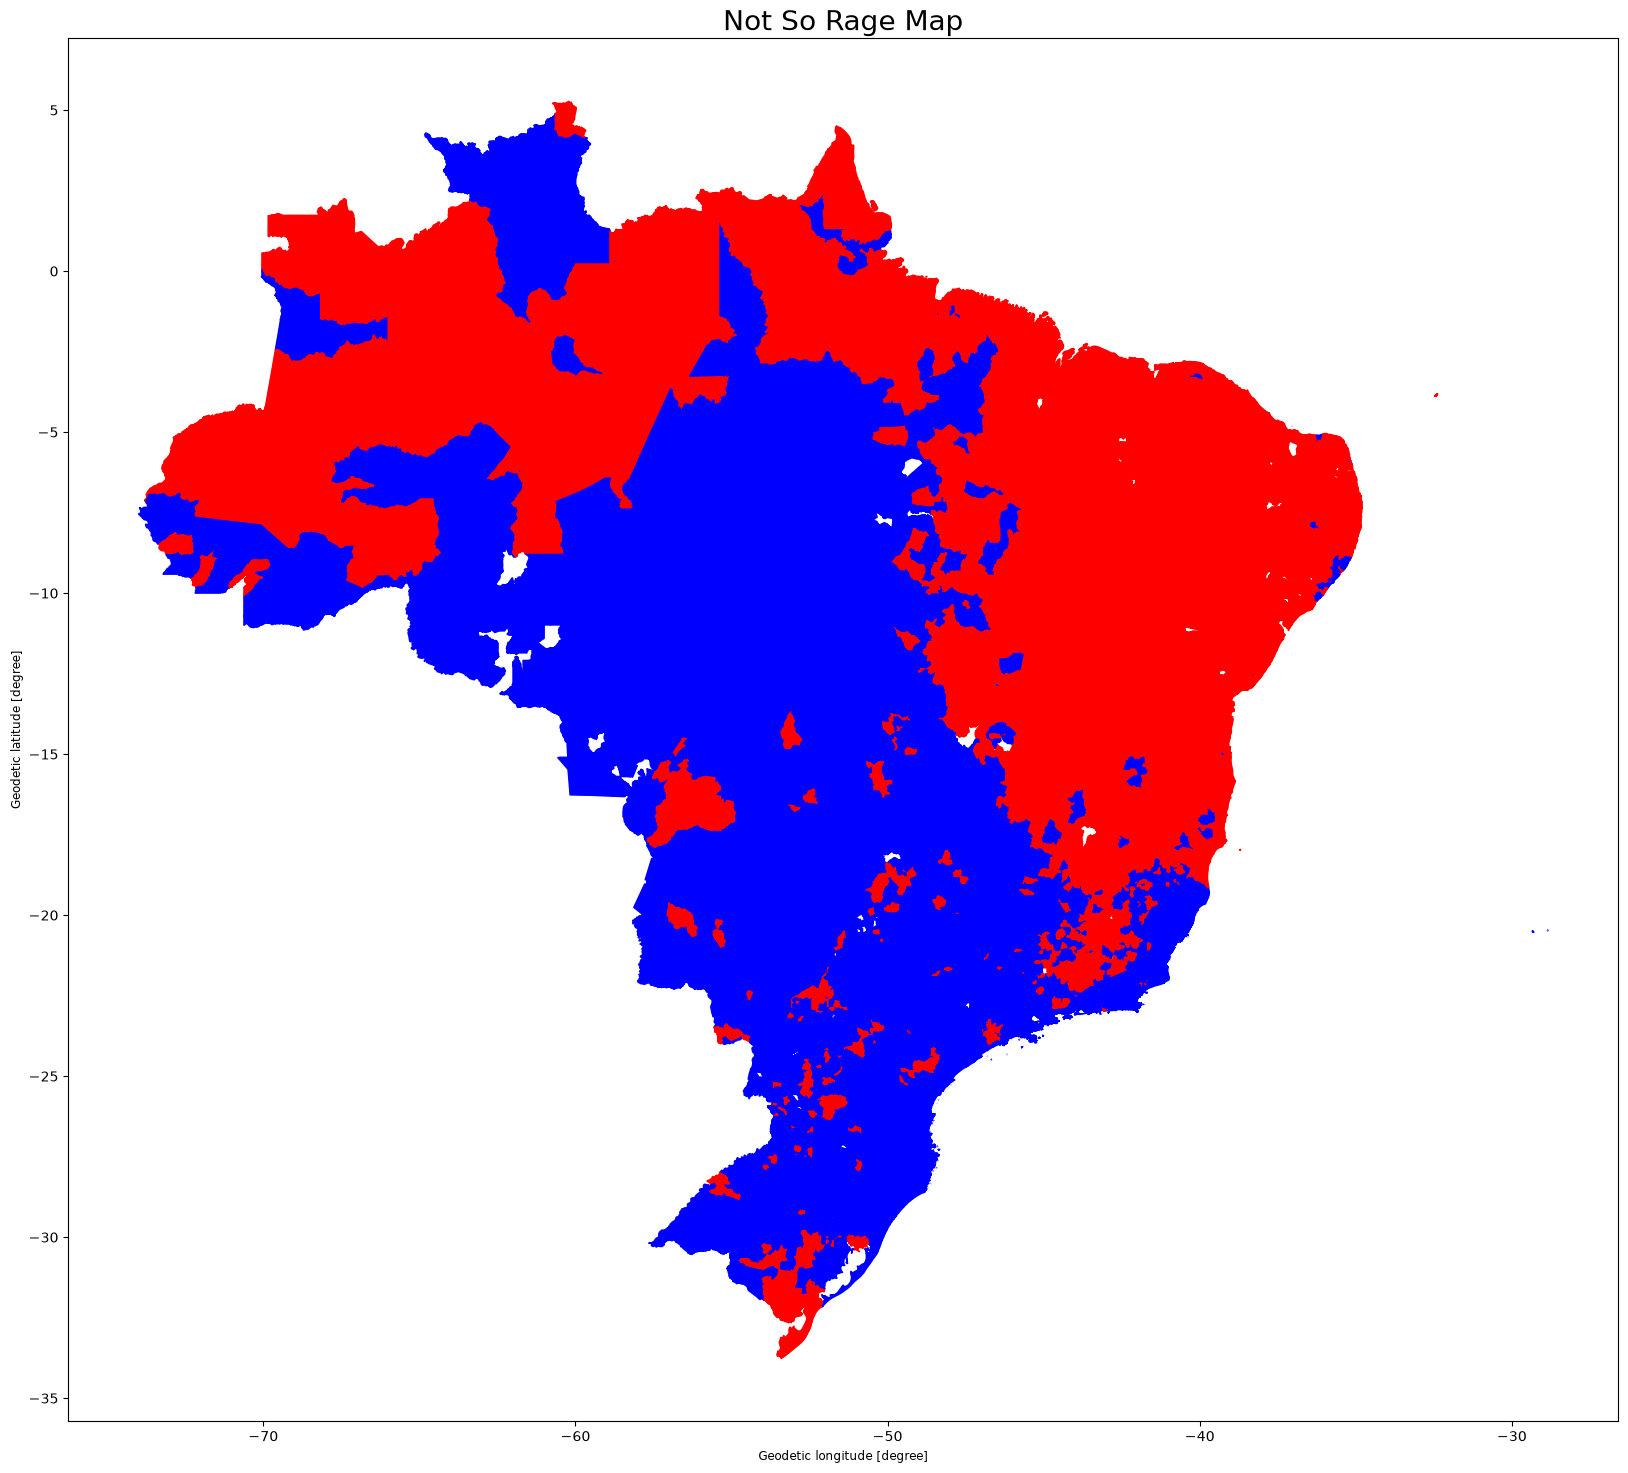

In [47]:
fig, ax = plt.subplots(figsize=(20,20))
mapa_vot.plot(column='13_bin', color=mapa_vot['13_color'], edgecolor=mapa_vot['13_color'], ax=ax)
# ax.set_axis_off();
ax.set_title("Not So Rage Map", fontsize=20)
plt.savefig('rage_map_mun.pdf')

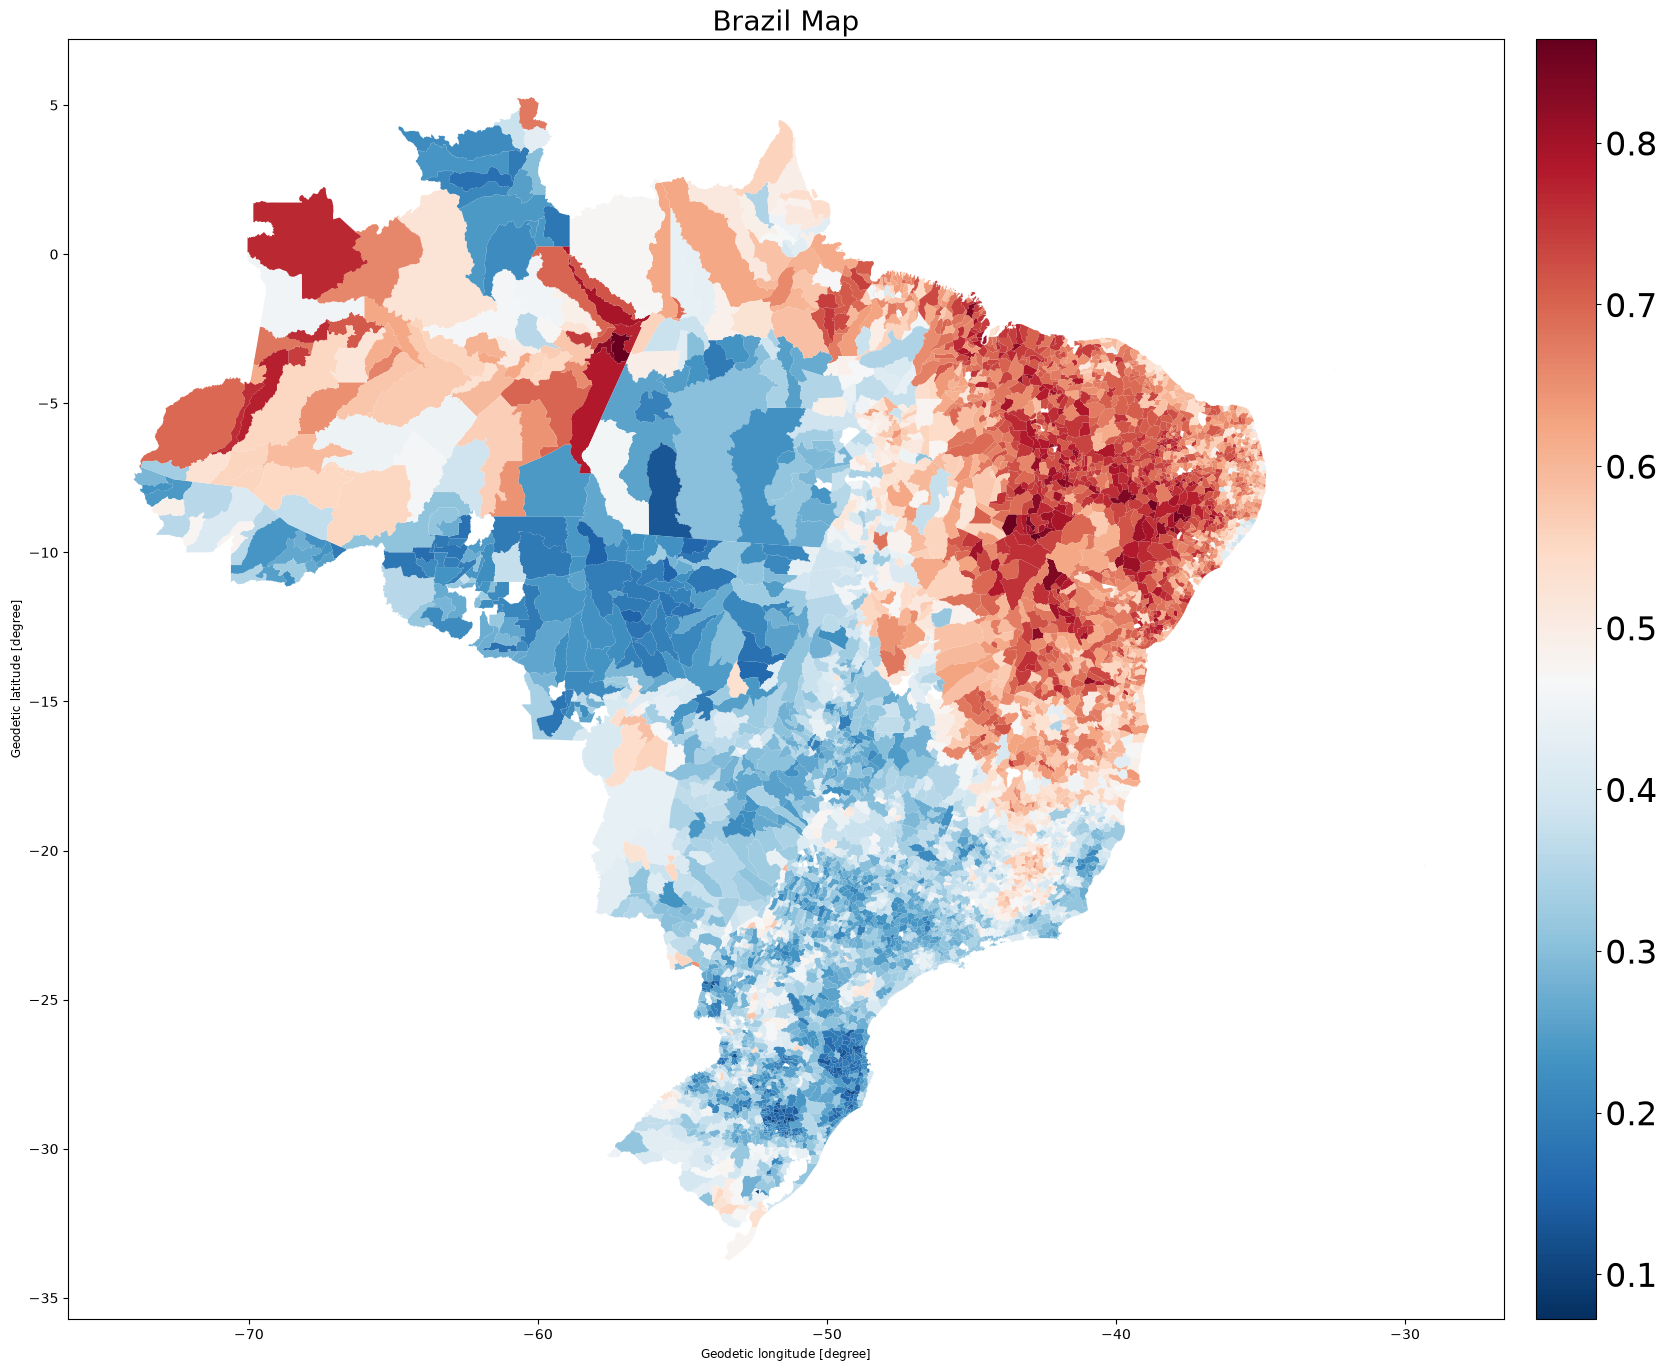

In [48]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax = plt.subplots(figsize=(20,20))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.1)
mapa_vot.plot(column=13, cmap='RdBu_r', legend=True, edgecolor='none', ax=ax, cax=cax)
# mapa_vot.apply(lambda x: ax.annotate(text=x['13r'], xy=x.geometry.centroid.coords[0], ha='center', color='black', fontsize=18, fontweight='bold'), axis=1);
# ax.set_axis_off();
for t in cax.get_yticklabels():
   t.set_fontsize(24)
ax.set_title("Brazil Map", fontsize=20)
# ax.set_caption('teste')
plt.savefig('brazil_map.pdf')